# Basketball: first real historical evaluation

This notebook displays the audited **B002 aggregate evidence** for NBA, NCAA men and NCAA women. It does not load private observations, individual predictions or fitted assets, and it performs **zero model fits**. Its separate invented example tests information-time contracts.

[Study](../docs/BASKETBALL_FOUNDATION.md) · [League tables](../docs/BASKETBALL_RESULTS.md) · [Model card](../docs/BASKETBALL_MODEL_CARD.md)

The 2025 and 2026 folds selected the recipes, so they are development evidence. Completed tracks use reconstructed 24-hour statistical release assumptions; T−60 is primary, T−24h separate. No MARKET advantage or prospective profit is established.

In [1]:
from pathlib import Path
import json
import sys
from html import escape
from IPython.display import display, HTML, SVG

here=Path.cwd().resolve()
root=next(p for p in (here,*here.parents) if (p/'examples/basketball_contracts/evidence.py').is_file())
if str(root) not in sys.path:
    sys.path.insert(0,str(root))
from examples.basketball_contracts.evidence import load_evidence, selected_season_rows
from examples.basketball_contracts.__main__ import walkthrough
evidence=load_evidence(root/'docs/evidence/2026-10-27-basketball-b002.json')
owner=evidence['owner_execution']
print(json.dumps({k:owner[k] for k in ('completed_native_fit_units','fit_units_by_league','fit_units_by_kind','reconstructed_validation_tracks','current_forecast_rows','current_distinct_games','actual_orders','profit')},indent=2))
assert owner['completed_native_fit_units']==172
assert owner['actual_orders']==0 and owner['profit'] is None

{
  "completed_native_fit_units": 172,
  "fit_units_by_league": {
    "nba": 54,
    "ncaam": 59,
    "ncaaw": 59
  },
  "fit_units_by_kind": {
    "calibrator": 64,
    "classifier": 64,
    "scores": 44
  },
  "reconstructed_validation_tracks": 6,
  "current_forecast_rows": 110,
  "current_distinct_games": 61,
  "actual_orders": 0,
  "profit": null
}


## Selected full-cohort probability models, by season

NBA selected the regularized strength model; both college tracks selected the regularized combined representation. These are the full basketball cohorts. Their scores cannot be compared with a MARKET result on a smaller set of games. The separate point heads use Ridge, including score selections associated with a CatBoost classifier recipe.

In [2]:
selected=selected_season_rows(evidence)
labels={'nba':'NBA','ncaam':'NCAA men','ncaaw':'NCAA women'}
header=['League','Season ending','Games','Selected probability recipe','Log loss','Brier','Correct / incorrect','Calibration error']
body=[]
for row in selected:
    body.append([labels[row['league']],str(row['validation_season']),f"{row['n']:,}",row['recipe'],f"{row['log_loss']:.6f}",f"{row['brier']:.6f}",f"{row['correct']:,} / {row['incorrect']:,}",f"{row['ece_10_fixed_bins']:.6f}"])
table='<table><thead><tr>'+''.join('<th>'+escape(v)+'</th>' for v in header)+'</tr></thead><tbody>'
table+=''.join('<tr>'+''.join('<td>'+escape(v)+'</td>' for v in row)+'</tr>' for row in body)+'</tbody></table>'
display(HTML(table))
assert len(selected)==6

League,Season ending,Games,Selected probability recipe,Log loss,Brier,Correct / incorrect,Calibration error
NBA,2025,"1,248",basketball_strength,0.612542,0.212630,811 / 437,0.030820
NBA,2026,"1,249",basketball_strength,0.602398,0.207240,846 / 403,0.030582
NCAA men,2025,"5,758",basketball_combined,0.530652,0.179246,"4,157 / 1,601",0.014187
NCAA men,2026,"5,749",basketball_combined,0.533493,0.180642,"4,121 / 1,628",0.020576
NCAA women,2025,"5,280",basketball_combined,0.462930,0.153622,"4,036 / 1,244",0.016230
NCAA women,2026,"5,621",basketball_combined,0.467299,0.155838,"4,263 / 1,358",0.023989


## Season stability within each league

Each panel displays the selected probability recipe's historical log loss. Lower is better within the same league and cohort. League difficulty and base rates differ; the vertical axes are separate. The figure does not compare MARKET or certify a prospective gain.

Selected historical log loss; SVG fallback follows.

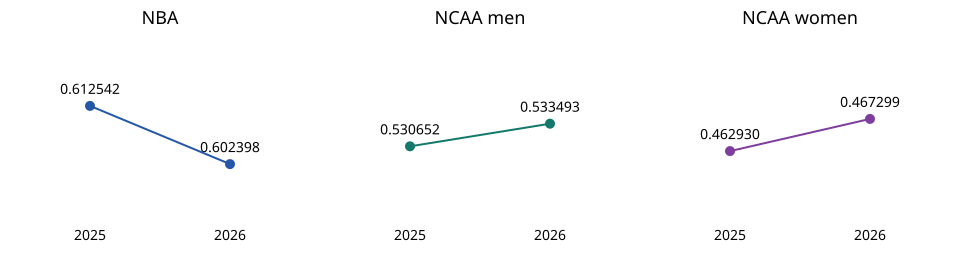

In [3]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
fig=make_subplots(rows=1,cols=3,subplot_titles=[labels[k] for k in ('nba','ncaam','ncaaw')])
colors=['#2457A7','#13796B','#7D3E9D']
svg=['<svg xmlns="http://www.w3.org/2000/svg" width="960" height="270" viewBox="0 0 960 270"><rect width="960" height="270" fill="white"/>']
for i,league in enumerate(('nba','ncaam','ncaaw')):
    rows=sorted((r for r in selected if r['league']==league),key=lambda r:r['validation_season'])
    years=[r['validation_season'] for r in rows]
    losses=[r['log_loss'] for r in rows]
    fig.add_trace(go.Scatter(x=years,y=losses,mode='lines+markers+text',text=[f'{v:.6f}' for v in losses],textposition='top center',line_color=colors[i],name=labels[league],showlegend=False),row=1,col=i+1)
    fig.update_xaxes(tickmode='array',tickvals=years,ticktext=['2025','2026'],title_text='Season ending',row=1,col=i+1)
    lo,hi=min(losses)-.008,max(losses)+.008
    fig.update_yaxes(range=[lo,hi],title_text='Log loss',row=1,col=i+1)
    offset=320*i
    svg.append(f'<text x="{offset+160}" y="24" text-anchor="middle" font-family="sans-serif" font-size="18">{labels[league]}</text>')
    coords=[]
    for x,year,v in zip((offset+90,offset+230),years,losses):
        y=210-(v-lo)/(hi-lo)*150
        coords.append((x,y))
        svg.append(f'<circle cx="{x}" cy="{y}" r="5" fill="{colors[i]}"/><text x="{x}" y="{y-12}" text-anchor="middle" font-family="sans-serif" font-size="14">{v:.6f}</text><text x="{x}" y="240" text-anchor="middle" font-family="sans-serif" font-size="14">{year}</text>')
    svg.append(f'<line x1="{coords[0][0]}" y1="{coords[0][1]}" x2="{coords[1][0]}" y2="{coords[1][1]}" stroke="{colors[i]}" stroke-width="2"/>')
svg.append('</svg>')
fig.update_layout(height=330,width=1050,template='plotly_white',margin=dict(t=45,b=55,l=45,r=25),title_text='Selected model: historical log loss by league and validation season')
display({'application/vnd.plotly.v1+json':json.loads(fig.to_json()),'text/plain':'Selected historical log loss; SVG fallback follows.'},raw=True)
display(SVG(''.join(svg)))
figure_completed=True

## What the matched MARKET evidence does and does not support

At T−60, NBA has seven and six matched games in the two historical seasons; NCAA men has zero and 118; NCAA women has 23 and 13. The learned MARKET-only and integrated classifiers could not fit with the available matched training history. No league qualified an advantage.

The men's style-model difference on the 118 ending-2026 games is −0.006053 log loss versus MARKET, with a descriptive 95% seven-day-block interval from −0.041032 to 0.035094. Thirteen blocks and the missing earlier season prevent qualification. Full tables and other model contrasts remain in the aggregate export.

B002's 110 current forecast rows span 61 games. Every row is an early outlook, every qualified current price is missing, and no forecasted game had settled at issue. Retrospective current-season evaluation is separate from prospective performance.

In [4]:
market_counts=[]
for track in evidence['tracks']:
    if track['horizon_minutes']!=60:
        continue
    for year in (2025,2026):
        rows=[r for r in track['season_scorecards'] if r['validation_season']==year and r['cohort']=='matched_MARKET' and r['recipe']=='MARKET_raw']
        market_counts.append({'league':labels[track['league']],'season_ending':year,'matched_games':rows[0]['n'] if rows else 0})
print(json.dumps(market_counts,indent=2))
assert evidence['evaluation']['market_advantage_established'] is False
assert owner['qualified_current_market_probabilities']==0
assert owner['prospectively_settled_games_at_issue']==0

[
  {
    "league": "NBA",
    "season_ending": 2025,
    "matched_games": 7
  },
  {
    "league": "NBA",
    "season_ending": 2026,
    "matched_games": 6
  },
  {
    "league": "NCAA men",
    "season_ending": 2025,
    "matched_games": 0
  },
  {
    "league": "NCAA men",
    "season_ending": 2026,
    "matched_games": 118
  },
  {
    "league": "NCAA women",
    "season_ending": 2025,
    "matched_games": 23
  },
  {
    "league": "NCAA women",
    "season_ending": 2026,
    "matched_games": 13
  }
]


## Separate public contract demonstration — invented probabilities only

The next cell uses invented game identities and probabilities to verify league separation, time cutoffs, stale-quote rejection and the protected 2027 selection boundary. Its Brier scores are software examples. They are not the real B002 model results above.

In [5]:
synthetic=walkthrough()
assert synthetic['synthetic_only'] is True and synthetic['model_fits']==0
assert synthetic['protected_2027_selection_rejected'] is True
assert synthetic['network_calls']==synthetic['paid_requests']==synthetic['orders']==0
print(json.dumps({'synthetic_only':True,'model_fits':0,'protected_2027_selection_rejected':True,'invented_examples':[r['invented_score_demonstration'] for r in synthetic['reports']]},indent=2))

{
  "synthetic_only": true,
  "model_fits": 0,
  "protected_2027_selection_rejected": true,
  "invented_examples": [
    {
      "league": "nba",
      "games": 1,
      "synthetic_model_brier": 0.16000000000000003,
      "MARKET_brier": 0.20249999999999996,
      "cohort_sha256": "de62b4e01fafec0bfc63f0f5756a1caed8f8f5a0a4cdb11d8981f4c3308b0a0b",
      "profit": null,
      "profit_status": "unavailable_without_predecision_execution_and_settlement_evidence"
    },
    {
      "league": "ncaam",
      "games": 1,
      "synthetic_model_brier": 0.16000000000000003,
      "MARKET_brier": 0.20249999999999996,
      "cohort_sha256": "335b8ae2bb0e715002239420b57540642f81566f5f9f1ef518e07a1ac98a1954",
      "profit": null,
      "profit_status": "unavailable_without_predecision_execution_and_settlement_evidence"
    },
    {
      "league": "ncaaw",
      "games": 1,
      "synthetic_model_brier": 0.16000000000000003,
      "MARKET_brier": 0.20249999999999996,
      "cohort_sha256": "80c512c

## Decision and next milestone

The completed run supports further basketball research and preserves an honest negative/incomplete MARKET result. B003 owner execution is pending. Planned work targets cached MARKET enumeration, exact work reuse, repeated feature preparation and prospective monitoring. Player/lineup, graph, neural and distributional basketball models remain unimplemented research directions.

The final cell executes after the figure and verifies that real owner aggregates and synthetic examples remain separate. The runner then saves and reopens this notebook to inspect execution order, native Plotly/SVG persistence and completion.

In [6]:
assert figure_completed
assert owner['completed_native_fit_units']==172 and synthetic['model_fits']==0
assert evidence['evaluation']['current_outcomes_used_for_selection_or_fitting'] is False
assert evidence['next_release']['owner_status']=='pending'
assert all(not v for v in evidence['publication_boundary'].values())
print('PUBLIC_REVIEW_COMPLETE: aggregate evidence inspected; zero local model fits; native figure and subsequent cells completed.')

PUBLIC_REVIEW_COMPLETE: aggregate evidence inspected; zero local model fits; native figure and subsequent cells completed.
